# E59: Does a readout trained only on Pile text find the half-known values before the last block?

## The answer

We could not tell. We trained one linear readout per block on ordinary Pile text, seeking a label for the half-known values that uses neither the decomposition nor the model's output. The readouts did worse on unseen text than the model's head, and no block reached the possession bar. The construction check we filed turned out to be one the model's own output fails, so even a perfect readout would have stopped there. The "half-known" label still rests on the model's averaged output.


## What we were trying to test

The project asks whether a VPD decomposition can tell a fine-tune that strengthens something the original model already does from one that teaches it something new. An earlier experiment built a pair for this on the 67M model. Each window is Pile text with a rare marker token, then a key word, and the model must predict the key's value next. Both tasks use the same 32 keys.

- **Elicit map.** Each key's value is a word the original model's averaged prediction after the key already ranks 2nd to 20th. Averaged means the mean probability over 500 windows holding the key.
- **Cipher.** The same keys mapped to words the original model almost never predicts there.

The decomposition separates the two. Let only Γ, the causal-importance function, see the fine-tuned activations, with every subcomponent's weights kept at their original values. That recovers about three quarters of the elicit map's gain and about a quarter of the cipher's. But the label "half-known" was read off the model's own output ranks. A sceptic can say the pair was built to make the decomposition read high.

This experiment looked for a label from outside both. Jain et al. 2024, Definition 1, say a model possesses a capability when a linear readout trained on pretraining data recovers it from the model's activations.

- **Readout.** One linear map per block, from that block's 768-number output to scores over the 50,277-word vocabulary. Each is trained to predict the next token on random Pile windows, never on the task windows, with the paper's schedule of 4,000 optimiser steps.
- **Rank of a value.** At the answer position of the 97 held-out task windows, the value's place in the readout's scores, with 1 the top word. A key's rank is the lower median over its windows, about three per key. So this is a per-window statistic, not the averaged one the pair was built with.
- **Possessed at a block.** At least 24 of the 32 keys have median rank 20 or better, the band the elicit pair was built with.
- **Construction check.** At the last block the readout should agree with the model's own output. At least 24 elicit values should sit at rank 2 to 20, and at least 24 cipher values should rank worse than 100th, meaning a rank number above 100. If it fails, the run stops. It was filed without measuring whether the model's own logits meet it.
- **Readout quality.** The last block's loss on unseen Pile text must come within 0.1 nats of a linearised head. That head is the model's own unembedding with the final norm's per-token scale fixed at its mean. It is a linear map the readout could learn, so a readout that cannot match it is badly fitted.

A second half was planned and never reached. On twelve saved fine-tunes it would remove the readout's direction for the target value at the answer position, and read what share of each fine-tune's gain is lost.

## What we expected, and why

- **The elicit values are held before the last block, the cipher's nowhere.** The elicit values are words the model already predicts after the key, so some earlier block should carry them in a direction a Pile-trained readout finds. The cipher's values are words the model never predicts there. If the readout found the elicit values only at the last block, "half-known" would just mean "what the output already says". We leaned medium on this.
- **Removing the readout's direction costs the elicit fine-tune more than the cipher.** That would show the elicit fine-tune's gain runs through what the original model already used. Lean medium.
- **The last block reproduces the construction.** Lean high: at the last block the readout is close to the unembedding, and this was the run's own check. We assumed the model itself would pass it and did not measure that first.

## Do the readouts fit unseen Pile text as well as their training text?


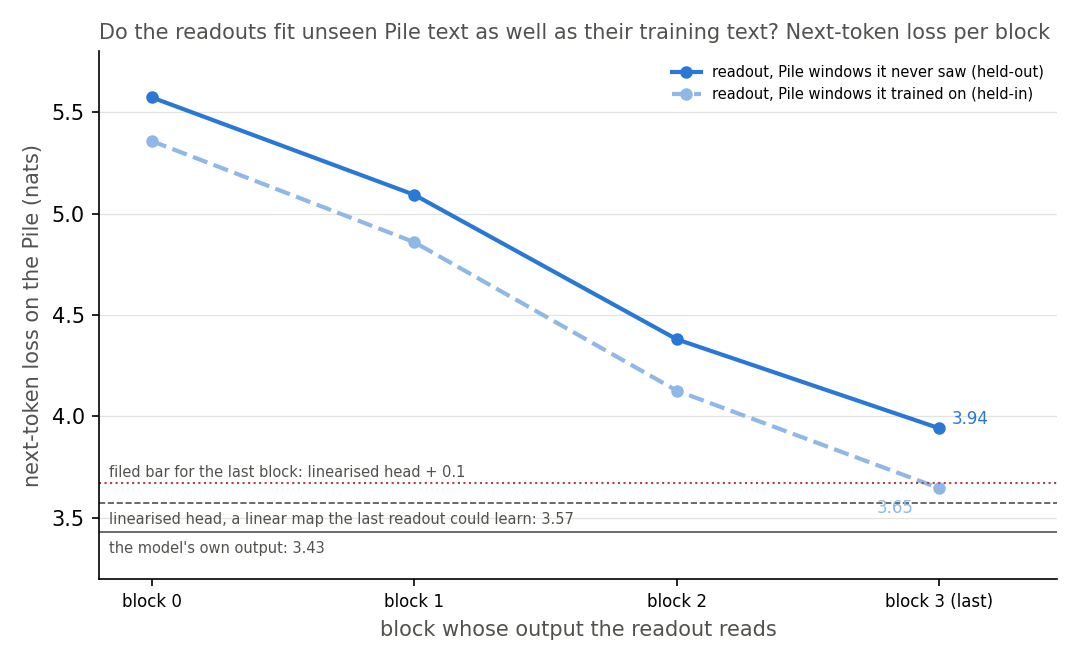

In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/jain_readout/figures")
display(Image(filename=str(FIG / "readout_loss.png")))

**Reading it.** No: the readout fits its training text and generalises worse. On Pile windows it never saw, the last block's readout reached 3.94 nats, 0.37 above the linearised head, against a bar of 0.1. On windows drawn from its training rows, it sat 0.07 above the head, inside the bar, so it is not under-fit on that text. The model and the linearised head read the same on both pools, so the gap belongs to the readout alone. Every block shows it: unseen text reads 0.22 to 0.30 nats worse than seen text.

Why it generalises worse was not measured. An advice report's hypothesis is the readout's size against its data. Each readout has one row of 768 weights for each of the 50,277 words, and a row learns where its word belongs mainly from tokens that have that word as the target. In 15 million training tokens, the rows of rare words see only a handful, so they might fit those examples rather than a rule. Jain et al. read a vocabulary of a few hundred, where their schedule would not meet this. No per-frequency split or token-count sweep tested it.

The head's own distance from the model, 0.14 nats, is a temperature difference and not a rank one. At any token its logits are a positive multiple of the model's. Its ranks matched the model's on every window except two of the cipher's, each off by one place, probably from rounding.

### Four jobs, four stops

All four ran on the cluster's free debug queue.

1. **The first job** reused 4.2 million Pile tokens about 3.7 times each. Its last readout scored about 3.2 on its training batches but 4.14 on unseen text, where the model scores 3.43. It overfit, so the training rows were widened until no token was seen more than once in expectation.
2. **The second job** stopped at an early check after 250 steps. The bar there had been set from one noisy batch of the first job, and it was missed by 0.009 nats. The bar was raised, since the check only exists to catch a readout that is not learning at all. The rerun was deterministic and read the same value, so the raised bar is what let it pass.
3. **The third job** trained cleanly on fresh rows and missed the quality bar, as in the figure. Its held-in reading points away from a bug and from under-training. The advice report read the gap as a sample-size limit and extrapolated to four to eight times the tokens, which the free queue's time limit does not allow; neither was tested.
4. **The fourth job** reloaded those saved readouts and read the task windows, with a rule fixed beforehand. A pass would stand, because a weak readout biases against the claim. A miss on the elicit side would read "unreadable". The construction check stayed a stop.


## Does any block's readout hold the elicit values, and none the cipher's?

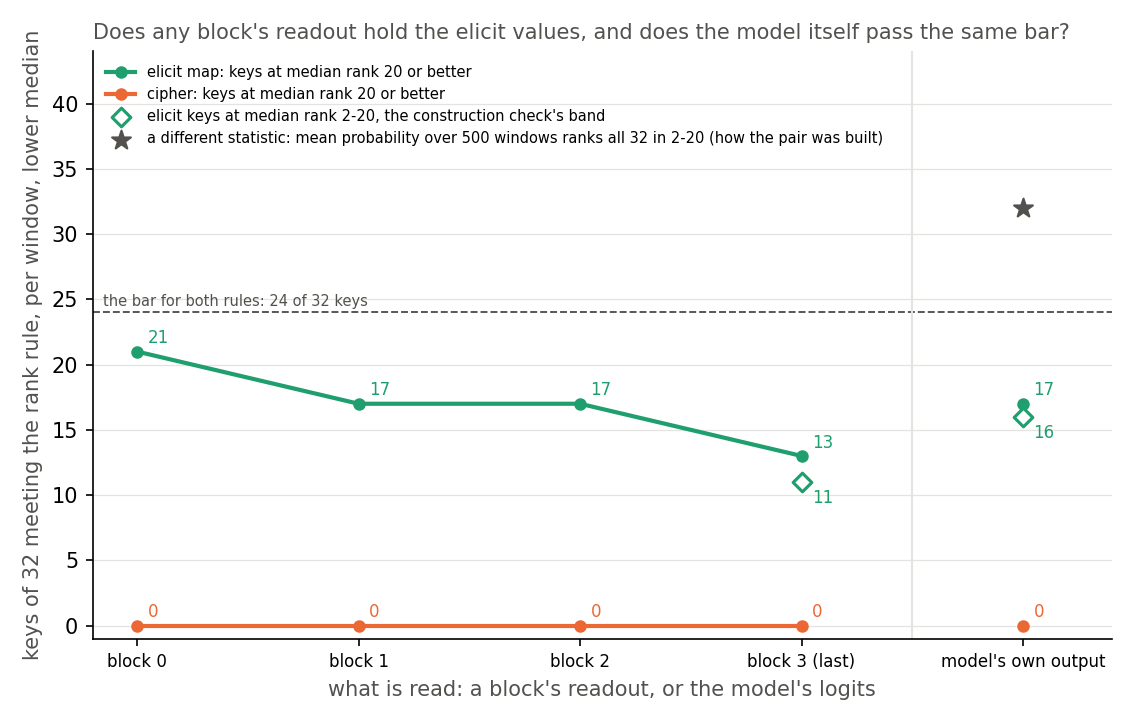

In [2]:
display(Image(filename=str(FIG / "possession.png")))

**Reading it.** No block holds the elicit map, and the last block fails the construction check, so the readout cannot answer the question. The green line counts keys whose value the readout ranks 20th or better. Block 0 comes closest, with 21 keys against the 24 needed. At the last block the readout puts 11 elicit values at rank 2 to 20; that miss stopped the run before the removal tests. The orange line is the cipher: no value reaches rank 20 at any block, and the typical cipher rank is several thousand.

The right-hand column is the reference, measured afterwards on the same windows and rules: the model's own logits. They put 16 values in the band and 17 at rank 20 or better, so neither readout nor model reaches 24. The check stays failed as filed, but even a perfect readout could not have met it. Each window's rank, then a median over about three windows, does not reproduce values picked by mean probability over 500 windows. That averaged statistic is the star, with all 32 in the band. So the readout reads 11 where the model reads 16, on a bar neither reaches. Those five keys are not shown to exceed noise.

The cipher result bears little weight. A weaker readout ranks every value worse, which pushes towards "not held", the very outcome the cipher side needed. And the cipher's values were chosen as words the model almost never predicts after the key, so any readout that tracks the model even roughly ranks them low. It agrees with the label, but it does not stand apart from the output ranks the label came from.

One odd feature: the elicit count falls with depth, from 21 keys at block 0 to 13 at the last. With about three windows per key and one readout seed, a change of four keys may be noise. If it is real, the simplest alternative is that the values are bigram-like. They were picked as words likely after the key on average, and the first block's readout may act like a table of next words after the key. The trend would then describe how the values were picked, not only the readout. That was not tested.


## What we learned

The question is still open. A next-token readout over the full vocabulary, trained on 15 million Pile tokens, does not match the 67M model's own head on unseen text. The filed construction check adds nothing about its quality, because the model's own logits fail it too. So this readout cannot say whether an earlier block holds the elicit values. For `GOALS.md`, the label "strengthens what the model half-knows" still rests on the original model's averaged output ranks. The new check limits that label. By each key's median window, the model ranks 17 of the 32 values at 20 or better. So "half-known" describes an average over windows more than a typical window. We have no label for the pair yet that is independent of both VPD and that output. The decomposition's separation of the pair stands as measured, but what it separates is still defined by the output.

## How compelling is the evidence

For the verdict "unreadable", strong, because the rules fixed beforehand say so: an elicit-side miss reads unreadable, and the readout also misses its loss bar by 0.37 nats. The construction check's miss by 13 keys is not evidence on its own, since the model misses the same bar by 8. For anything about the model, weak. The readout is blind to non-linear encodings, and it scores ranks among 50,277 words where the paper scores a few hundred. Each key has about three held-out windows, so a key's median rank is noisy, though the 24-key count absorbs some of that. One key draw, one model, one readout seed.

## Surprises

- The model's own logits fail the construction check, with 16 elicit keys in the band where 24 are needed. We expected a pass or a near pass and never measured it before filing, so the check was mis-specified. It stays failed as filed.
- The elicit count falls with depth, and the last block holds the fewest elicit values of any block. The bigram-like alternative was not tested.
- Fresh rows lowered the unseen loss but still left unseen text 0.30 nats worse than seen text. That vocabulary size rather than repetition is the limit is an advice report's hypothesis.

## What next

- **A small-vocabulary readout,** now approved by the user as the next experiment, E64. Restrict the readout's outputs to the table's values, as Jain et al. do with a few hundred outputs. If it holds the elicit values at an early block and not the cipher's, the label becomes independent; if only at the last, "half-known" means "what the output says". Its construction check must take the model's own per-window ranks as its reference, or it hits the same wall.
- **The same readout on four to eight times the tokens.** One to two hours of an L40 at the measured step time, so the normal queue or a paid card. It needs the user, the token multiple is an untested extrapolation, and the small vocabulary is the cheaper first try.
- **The graded ladder of tables.** Several tables over the same keys at different prior ranks. It keeps a behavioural label, but would show whether the decomposition's reading rises with how well the model knows the value.


## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| stage 0 inputs | saved states and the model's rates reproduce the earlier runs | all twelve states' sha256 and gains exact, difference 0 | pass |
| stage 0 readout loss | last-block held-out loss within 0.1 nats of the linearised head | 3.94 vs 3.57: over by 0.37; held-in over by 0.07 | miss, recorded, not a stop under the amended rule |
| P3 | last block: ≥ 24 elicit keys at rank 2-20, ≥ 24 cipher keys above 100 | elicit 11, cipher 32 | **fail**: the run stopped here; stands as filed |
| P3's rule on the model's own logits | a diagnostic, run afterwards, not a prediction | elicit 16, cipher 32 | fail: a perfect readout could not have met P3 |
| P1, elicit clause | elicit possessed at block 0, 1 or 2 | best block 0, 21 of 32 keys; none possessed; model's output 17 | unreadable, by the pre-set rule |
| P1, cipher clause | cipher possessed at no block | 0 of 32 keys at every block and at the model's output | holds; little weight |
| P2 | removal of the readout direction costs elicit more than cipher | — | not run |
| do-nothing, W0 control, last-block removal | random direction ≤ 0.05; W0 drops ≥ 0.3 nats | — | not run |

## Departures from the literature

- **Vocabulary.** Jain et al. read a vocabulary of a few hundred; this readout covers all 50,277 words. An advice report names that as why it is too weak on unseen text, a hypothesis.
- **Training data and position.** The paper trains the readout on data from the pretraining process and reads it on inputs carrying the task. We train on Pile next-token windows at every position from the second, and read only at the answer position after the marker and key.
- **Threshold.** The paper gives no number for "recovers the capability". Ours, median rank 20 or better for 24 of 32 keys, was filed before the run. It borrows the band the pair was built with but applies it per window, where the pair used mean probability over 500 windows, and the model's own output misses it.
- **Quality bar and reading rule.** The linearised-head bar and the rule that an elicit-side miss reads "unreadable" are ours, set after the first and third stops.
- **The causal check** removes the readout direction; the paper prunes neurons or fine-tunes in reverse. It was not reached.
- **Schedule** is the paper's; batch size 96 and the optimiser's defaults were filled in.

## Not run

- The removal tests on the twelve saved fine-tunes, the random-direction control, the original model's control and the last-block removal.
- Readouts on four to eight times the tokens, which need the normal queue or money.
- A small-vocabulary readout restricted to the table's values, closer to Jain et al.
- A per-frequency split of the held-in and held-out gap, which would test the rare-word hypothesis.
- The model's mean-probability rank on the 97 held-out windows alone, which would separate the statistic from the small pool of windows.
- A table of next words after the key alone, scored by the same rule, which would test the bigram-like alternative.
- Reverse fine-tuning, the paper's own causal tool.
- The own-step cipher at seeds 2 to 4, never saved by the earlier run.
- Another key draw, another readout seed, or Qwen.

## Provenance

MATS cluster L40, debug queue, $0. Jobs 48279, 48344, 48357 and 48412; job 48412 reloaded job 48357's readouts. Job 48453 read the model's own logits through the same rules. Results `experiments/jain_readout/results/run.json`, earlier versions in its git history, and `experiments/jain_readout/results/m1_check.json`; rules and dated amendments in `predictions.json`; figures from `experiments/jain_readout/plot.py`. Full record: `reports/analyses/2026-11-02_analysis_e59-jain-readout.md`.

## Revision note, 2026-11-02

Revised after an independent check (`reports/reviews/2026-11-02_review_e59-analysis.md`) and the measurement it asked for. The verdict is unchanged: closed, the earlier-block question unreadable, the construction check failed as filed. "The readout misses the model's own ranks" is gone, because the model's own logits fail the same rule. The possession figure now carries the model's counts and relabels the averaged statistic. "Memorised" and the rare-word cause became a measured gap and a hypothesis, and "under-fit" went. The fall with depth gained its noise caveat and its bigram-like alternative.
